# 08 - Make the final Catalogue

From the calibrated frame extract the photometry of the stars using Sextractor<br>
Apply light correction based on the results of the notebook 7.b<br>
Save the final catalogue combining Pycavi and Gaia photometries<br>

Done:<br>
* Sextractor running over the calibrated frame
* Read the catalogue (fits table)
* Read the Gaia catalogue
* Cross match the catalogues
* Create the final catalogue
* Create a merged catalogue of the sextractor images
* Clean the merged sextractor catalogue before comparing with Gaia
* First crossmatch the sextractor catalogues, then cross with Gaia
* Pack the code into the cell
* Add the zero point depending on the filter
* Validate r filter against SkyMapper
* Modify the zp cal notebook to save additional Gaia parameters
* Save the Gaia query as a raw query, create the clean versions as a different files, or add an additional column that defines if the source in each row is used in the clean version.
* Get the zp from the frame itself

ToDo:<br>
* Validate NB filter against VPHAS
* Add the sextractor parameters for the catalogue within the notebook
* For the same reason, minimize the sextractor default parameters. Think in the use for scamp
* Add a header for the fits catalogue. Inspire in vphas catalogues headers.

Notes:<br>
* Modified the papi_sextractor to allows the default parameter file to incorporated the position of the stars (XY_IMAGE, ALPHA/DELTA_J2000), as well as the Petro flux and mag.
* Petro mags shows the slopeless results when comparing Sextractor and Gaia mags.
* The zero points for photometry depend on the filter only: 21.40 for r_SDSS and 21.50 for NB in AB system.
* The merged catalogue includes the r_SDSS and NB filters, together with the Gaia data.
* The pycavi ra and dec were mean combined

In [1]:
import os
import sys
import logging

import numpy as np
import pandas as pd

sys.path.append(os.path.join(os.path.abspath(''), '..')) # to be removed in production
from pycavi import pycavi_tools, pycavi_astromatic_tools
from pycavi.pycavi_zpcal import get_files_dict


This will be executed when the package is imported.


/home/lceledon/Software/pycavi/Pycavi-main_Oct28_2024/Pycavi-main/notebooks/../papi/papi_sextractor.py:467: SyntaxWarning: invalid escape sequence '\.'
  _version_match = re.search(b"[Vv]ersion ([0-9\.])+", versionline)


In [ ]:
def getzpfromframe(framepath):
    hdr = fits.getheader(framepath)
    return hdr['HIERARCH ESO PYCAVI QC MAGZP']
    

In [ ]:
def load_catalogue(catalogue_path, extnumber=2):
    # the extension name varies with the catalogue. For the sextractor output, the extnumber is two
    hdul = fits.open(catalogue_path)
    table_data = hdul[extnumber].data
    hdul.close()
    output_table = Table(table_data)
    return output_table
    

In [ ]:
def crossmatch_catalogues(cat_1, cat_2, max_sep=1.0,
                          radec_tag_1=['raj2000', 'dej2000'], 
                          radec_tag_2=['raj2000', 'dej2000']):
    """
    Perform a crossmatch between catalogue 1 and catalogue 2.
    Both catalogue must be Astropy Table objects.
    
    Parameters:
        cat_1: Table with the catalogue to cross match
        cat_2: Table with the catalogue to cross match
        max_sep: maximum tolerance in arcsec between two sources to match. Default 1 arcsec
        radec_tag_1: list with the tags for the ra and dec in catalogue 1
        radec_tag_2: list with the tags for the ra and dec in catalogue 2
        
    Output:
        table_matched: Astropy Table with the cross matched sources.
    """
    # first check which catalogue is the longer
    # assing the catalogues and tag acordingly
    if len(cat_1) >= len(cat_2):
        cat_long = cat_1
        cat_short = cat_2
        radec_long = radec_tag_1
        radec_short = radec_tag_2
    else:
        cat_long = cat_2
        cat_short = cat_1
        radec_long = radec_tag_2
        radec_short = radec_tag_1
        
    # do the cross match
    skycoord_long = SkyCoord(ra=cat_long[radec_long[0]]*u.degree, dec=cat_long[radec_long[1]]*u.degree)
    skycoord_short = SkyCoord(ra=cat_short[radec_short[0]]*u.degree, dec=cat_short[radec_short[1]]*u.degree)
    
    max_sep_thresh = max_sep * u.arcsec
    idx, d2d, _ = skycoord_long.match_to_catalog_sky(skycoord_short)
    sep_constraint = d2d < max_sep_thresh

    matches_short = cat_short[idx[sep_constraint]]

    # create the combined catalogue
    table_short_matches = {}
    for col in cat_short.colnames:
        aux_arr = 1.0*np.arange(len(cat_long))
        aux_arr[:] = np.nan
        aux_arr[sep_constraint] = matches_short[col]
        table_short_matches[col] = aux_arr

    table_short_matches = Table(table_short_matches)
    table_matched = hstack([cat_long, table_short_matches])
    return table_matched


In [ ]:
def clean_merged_catalogue(merged_catalogue):
    """
    Clean the merged catalogue by removing sources that were not detected on all the catalogues.
    Average the celestial positions but keep the rest of columns untouched
    """
    # select the ra and dec columns from the input table
    ra = {}
    de = {}
    tags = []
    for col in merged_catalogue.colnames:
        if 'ALPHA_J2000' in col:
            tag = col[12:]  # the filter tag, eg, r_SDSS
            tags.append(tag)
            racol = 'ALPHA_J2000_'+tag
            decol = 'DELTA_J2000_'+tag
            ra[tag]=merged_catalogue[racol]
            de[tag]=merged_catalogue[decol]
    
    # remove the entries where there is a nan
    sel_nan = np.ones(len(merged_catalogue), dtype=bool)
    for tag in ra.keys():
        ra_data = ra[tag]
        sel_tag = np.isnan(ra_data)
        sel_nan = sel_nan & ~sel_tag
            
    # clean the catalogue
    clean_catalogue = merged_catalogue[sel_nan]
    
    # combine the ra and dec
    ra_comb = None
    de_comb = None
    for tag in tags:
        if ra_comb is None:
            ra_comb = clean_catalogue['ALPHA_J2000_'+tag]
            de_comb = clean_catalogue['DELTA_J2000_'+tag]
        else:
            ra_comb = np.vstack((ra_comb, clean_catalogue['ALPHA_J2000_'+tag])).T
            de_comb = np.vstack((de_comb, clean_catalogue['DELTA_J2000_'+tag])).T
    ra_mean = np.mean(ra_comb, axis=1)
    de_mean = np.mean(de_comb, axis=1)
    
    # remove alpha/delta j2000 columns
    clean_catalogue.remove_columns(['ALPHA_J2000_'+tag for tag in tags])
    clean_catalogue.remove_columns(['DELTA_J2000_'+tag for tag in tags])
    
    # add mean alpha and delta
    clean_catalogue['raj2000'] = ra_mean
    clean_catalogue['dej2000'] = de_mean
    
    return clean_catalogue

In [6]:
# set the directory folders
config_dir = os.getcwd()+'/../config/'
config = pycavi_tools.read_pycavi_config(config_dir)

observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_std_dir = config['Directories']['reduced_std_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']

log_file_swarp = log_dir + "/pymeffpp_zpcal_check.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# At this point it is believed that the data reduction process
# should be closely monitored, so we calibrate target/filter sets,
# that is each data partition, one by one.
#
filters = []
reject_observations = []
dir_name = config['Directories']['cal_dir_name']
zpcal_dict = get_files_dict(reduced_std_dir, reduced_science_dir, dir_name, filters, reject_observations)

observation_tags = list(set(zpcal_dict.keys()))
observation_tags.sort()    # Needed to ensure same index in every run
images_to_check = []
for i in range(len(observation_tags)):
    logging.debug("index: {} observation_tag: {}".format(i, observation_tags[i]))
    for j in range(len(zpcal_dict[observation_tags[i]])):
        images_to_check.append(zpcal_dict[observation_tags[i]][j])

for i in range(len(images_to_check)):
    logging.info("index: {} -- file: {}".format(i, images_to_check[i]))


2024-10-29 12:38:54,339:INFO:index: 0 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_NB_659.coadd.fits
2024-10-29 12:38:54,339:INFO:index: 1 -- file: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori_r_SDSS.coadd.fits


In [12]:
redo_sextractor = True
idx_selected = []    # Keep empty to check all files

merged_table = None  # as it creates the sextractor catalogues, starts inmediately to do the crossmatch with the 
                     # previous catalogue
for i in range(len(images_to_check)):
    
    target = images_to_check[i]
    # skip indices not in list idx_selected
    if not (i in idx_selected or not idx_selected):
        continue
    
    sextractor_dir_path = "/".join(target.split("/")[:-2])+'/'+config['Directories']['sex_dir_name']
    try:
        logging.info("Atempting to create the Sextractor_dir folder: {}".format(reduced_science_dir+target_name))
        os.mkdir(sextractor_dir_path)
        logging.info("Folder created")
    except:
        logging.info("Folder already exists")
    
    # check the filter of each target
    target_filter = None
    if 'r_SDSS' in target:
        target_filter = 'r_SDSS'
    elif 'NB_659' in target:
        target_filter = 'NB_659'
    # check the name of the target itself
    target_name = target.replace(target_filter,'')[:-12]
    
    # run sextractor on frame
    ready_to_sextract = pycavi_astromatic_tools.prepare_to_sextract(target, redo_sextractor)

    # we tune some parameters for sextractr
    special_pars = {}
    special_pars["SATUR_KEY"] = "SATLEVEL"   # FITS keyword giving saturation value
    special_pars["DETECT_MINAREA"] = 5       # minimum number of pixels above threshold
    special_pars["DETECT_MAXAREA"] = 0       # maximun number of pixels above threshold
    special_pars["DETECT_THRESH"] = 5.0      # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
    special_pars["ANALYSIS_THRESH"] = 5.0    # <sigmas> or <threshold>,<ZP> in mag.arcsec-2
    special_pars["SEEING_FWHM"] = 1.2        # stellar FWHM in arcsec (we give here typical not so good value)
    special_pars["PHOT_APERTURES"] = 5       # MAG_APER aperture diameter(s) in pixels
    special_pars["MAG_ZEROPOINT"] = getzpfromframe(target)    # magnitude zero-point from the frames header
    special_pars["GAIN"] =  1.0              # detector gain in e-/ADU - if DN in e/s then 1.0
    special_pars["MEMORY_OBJSTACK"] = 6000   # number of objects in stack [3000]
    special_pars["MEMORY_PIXSTACK"] = 600000 # number of pixels in stack [300000]
    
    if ready_to_sextract:
        pycavi_astromatic_tools.run_sextractor_on_target(images_to_check[i], sextractor_dir_path, special_pars)
    
    # sextractor is done
    logging.info("SExtractor finished on image {}".format(target.split("/")[-1]))
    
    # start the cross matching process
    # add the filter tag to each column in the table to differentiate from the other data
    if merged_table is None:
        merged_table = load_catalogue(target[:-5]+'.cat')
        # add the filter tag to each column in the catalogue to make them unique
        for col in merged_table.colnames:
            merged_table.rename_column(col, col+'_'+target_filter)
        # save the filter tag that will identify the merged catalogue from here on
        merged_filter = target_filter
    else:
        single_table = load_catalogue(target[:-5]+'.cat')
        # update the column names by adding the filter tag
        for col in single_table.colnames:
            single_table.rename_column(col, col+'_'+target_filter)
        # defines the ra and dec tags for the single catalogue
        radec_tag_single = ['ALPHA_J2000_'+target_filter, 'DELTA_J2000_'+target_filter]
        radec_tag_merged = ['ALPHA_J2000_'+merged_filter, 'DELTA_J2000_'+merged_filter]
        merged_table = crossmatch_catalogues(merged_table, single_table, 
                                             radec_tag_1=radec_tag_merged, radec_tag_2=radec_tag_single)

# Clean merged table
savename = target_name + '_merged_catalogue.fits'
clean_table = clean_merged_catalogue(merged_table)

# cross match with Gaia and save
target_name_split = target_name.split('/')
query_gaia = '/'.join(target_name_split[:-1])+'/gaia3_qry_{}_raw.csv'.format(target_name_split[-1])
gaia_catalogue = pd.read_csv(query_gaia)
gaia_catalogue = Table.from_pandas(gaia_catalogue)

# rename ra and dec column in gaia catalogue for consistency
gaia_catalogue.rename_column('ra', 'raj2000')
gaia_catalogue.rename_column('ra_error', 'raj2000_error')
gaia_catalogue.rename_column('dec', 'dej2000')
gaia_catalogue.rename_column('dec_error', 'dej2000_error')

for col in gaia_catalogue.colnames:
    gaia_catalogue.rename_column(col, col+'_gaia')

merged_clean_gaia = crossmatch_catalogues(clean_table, gaia_catalogue, 
                                          radec_tag_1=['raj2000', 'dej2000'], 
                                          radec_tag_2=['raj2000_gaia', 'dej2000_gaia'])

merged_clean_gaia.write(savename, format='fits', overwrite=True)

logging.info("-------Done-------")

2024-10-29 12:56:37,317:INFO:Atempting to create the Sextractor_dir folder: /home/lceledon/Investigacion/OmegaCam/Work_dir//science//home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori
2024-10-29 12:56:37,318:INFO:Folder already exists
2024-10-29 12:56:37,318:INFO:Running Sextractor on image CN_Ori_NB_659.coadd.fits
2024-10-29 12:56:37,321:INFO:Moving to target's directory: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir
2024-10-29 12:56:37,321:INFO:sextractor.config[SATUR_KEY] = SATLEVEL
2024-10-29 12:56:37,322:INFO:sextractor.config[DETECT_MINAREA] = 5
2024-10-29 12:56:37,322:INFO:sextractor.config[DETECT_MAXAREA] = 0
2024-10-29 12:56:37,323:INFO:sextractor.config[DETECT_THRESH] = 5.0
2024-10-29 12:56:37,323:INFO:sextractor.config[ANALYSIS_THRESH] = 5.0
2024-10-29 12:56:37,323:INFO:sextractor.config[SEEING_FWHM] = 1.2
2024-10-29 12:56:37,324:INFO:sextractor.config[PHOT_APERTURES] = 5
2024-10-29 12:56:37,324:INFO:sextract

sextractor_base_dir: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir


2024-10-29 12:56:50,678:INFO:SExtractor finished on image CN_Ori_NB_659.coadd.fits
2024-10-29 12:56:50,693:INFO:Atempting to create the Sextractor_dir folder: /home/lceledon/Investigacion/OmegaCam/Work_dir//science//home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir/CN_Ori
2024-10-29 12:56:50,693:INFO:Folder already exists
2024-10-29 12:56:50,694:INFO:Running Sextractor on image CN_Ori_r_SDSS.coadd.fits
2024-10-29 12:56:50,696:INFO:Moving to target's directory: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir
2024-10-29 12:56:50,696:INFO:sextractor.config[SATUR_KEY] = SATLEVEL
2024-10-29 12:56:50,696:INFO:sextractor.config[DETECT_MINAREA] = 5
2024-10-29 12:56:50,697:INFO:sextractor.config[DETECT_MAXAREA] = 0
2024-10-29 12:56:50,697:INFO:sextractor.config[DETECT_THRESH] = 5.0
2024-10-29 12:56:50,697:INFO:sextractor.config[ANALYSIS_THRESH] = 5.0
2024-10-29 12:56:50,698:INFO:sextractor.config[SEEING_FWHM] = 1.2
2024-10-29 12:56:50,6

py-sextractor.cat --> CN_Ori_NB_659.coadd.cat
sextractor_base_dir: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CN_Ori/Calibration_dir


2024-10-29 12:57:02,581:INFO:SExtractor finished on image CN_Ori_r_SDSS.coadd.fits


py-sextractor.cat --> CN_Ori_r_SDSS.coadd.cat


2024-10-29 12:57:02,822:INFO:-------Done-------


## Checking the output catalogue

In [14]:
basedir = '/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CN_Ori/Calibration_dir/'
mergedtable = load_catalogue(basedir+'CN_Ori_merged_catalogue.fits', extnumber=1)
print(mergedtable.colnames)

['NUMBER_NB_659', 'FLUX_PETRO_NB_659', 'FLUXERR_PETRO_NB_659', 'MAG_PETRO_NB_659', 'MAGERR_PETRO_NB_659', 'FLUX_AUTO_NB_659', 'FLUXERR_AUTO_NB_659', 'MAG_AUTO_NB_659', 'MAGERR_AUTO_NB_659', 'FLUX_ISO_NB_659', 'FLUXERR_ISO_NB_659', 'MAG_ISO_NB_659', 'MAGERR_ISO_NB_659', 'A_IMAGE_NB_659', 'B_IMAGE_NB_659', 'THETA_IMAGE_NB_659', 'X_IMAGE_NB_659', 'Y_IMAGE_NB_659', 'XWIN_IMAGE_NB_659', 'YWIN_IMAGE_NB_659', 'ERRX2WIN_IMAGE_NB_659', 'ERRY2WIN_IMAGE_NB_659', 'ERRXYWIN_IMAGE_NB_659', 'ERRX2WIN_WORLD_NB_659', 'ERRY2WIN_WORLD_NB_659', 'ERRXYWIN_WORLD_NB_659', 'ERRAWIN_IMAGE_NB_659', 'ERRBWIN_IMAGE_NB_659', 'ERRTHETAWIN_IMAGE_NB_659', 'FLAGS_NB_659', 'FLAGS_WEIGHT_NB_659', 'FLAGS_WIN_NB_659', 'FWHM_IMAGE_NB_659', 'ELONGATION_NB_659', 'ELLIPTICITY_NB_659', 'CLASS_STAR_NB_659', 'NUMBER_r_SDSS', 'FLUX_PETRO_r_SDSS', 'FLUXERR_PETRO_r_SDSS', 'MAG_PETRO_r_SDSS', 'MAGERR_PETRO_r_SDSS', 'FLUX_AUTO_r_SDSS', 'FLUXERR_AUTO_r_SDSS', 'MAG_AUTO_r_SDSS', 'MAGERR_AUTO_r_SDSS', 'FLUX_ISO_r_SDSS', 'FLUXERR_ISO_r_S

### Astrometry check

The astrometry look good. There are a few stars that shows differences in position larger than 1 arcsec, which is weird because the cross match was supposed to be cut them from the final catalogue.<br>

Notes: This was done before the clean table process.

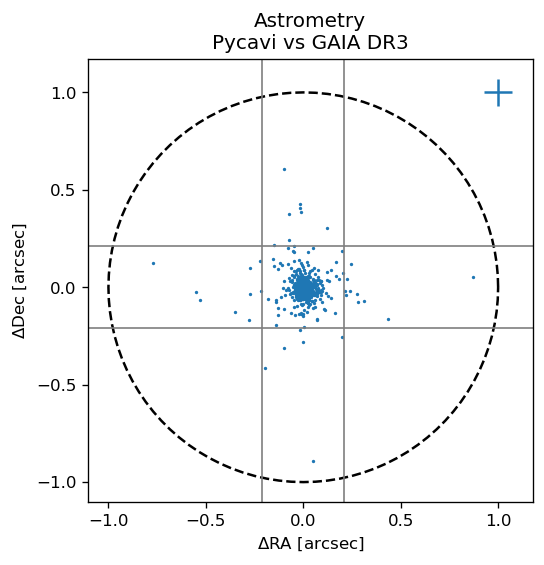

In [45]:
import matplotlib.pyplot as plt

ra_py = mergedtable['raj2000']
ra_gaia = mergedtable['raj2000_gaia']
de_py = mergedtable['dej2000']
de_gaia = mergedtable['dej2000_gaia']

ra_gaia_err = mergedtable['raj2000_error_gaia']
de_gaia_err = mergedtable['dej2000_error_gaia']

ra_gaia_err_mean = np.nanmean(ra_gaia_err)
de_gaia_err_mean = np.nanmean(de_gaia_err)

mean_de = np.nanmean(de_py)
t = np.linspace(0, 2*np.pi, 101)
x = np.cos(t)
y = np.sin(t)

fig, ax = plt.subplots(dpi=120)
ax.scatter(3600*(ra_py-ra_gaia), 3600*np.cos(mean_de*np.pi/180)*(de_py-de_gaia), s=1)
ax.plot(x, y, ls='--', color='black')
ax.axvline(-0.21, lw=1, color='tab:gray')
ax.axvline(0.21, lw=1, color='tab:gray')
ax.axhline(-0.21, lw=1, color='tab:gray')
ax.axhline(0.21, lw=1, color='tab:gray')

ax.errorbar(1,1,xerr=ra_gaia_err_mean, yerr=de_gaia_err_mean)
ax.set_xlabel(r'$\Delta$RA [arcsec]')
ax.set_ylabel(r'$\Delta$Dec [arcsec]')
ax.set_title('Astrometry\nPycavi vs GAIA DR3')
ax.set_aspect(1)

plt.show()

### Magnitudes check

The magnitudes does not show any unexpected feature. The slope of r_SDSS vs NB_659 magnitudes is slightly greater than 1. The stars that show separations larger than 1 arcsec does not show any remarkable position in the mag vs mag diagram<br>

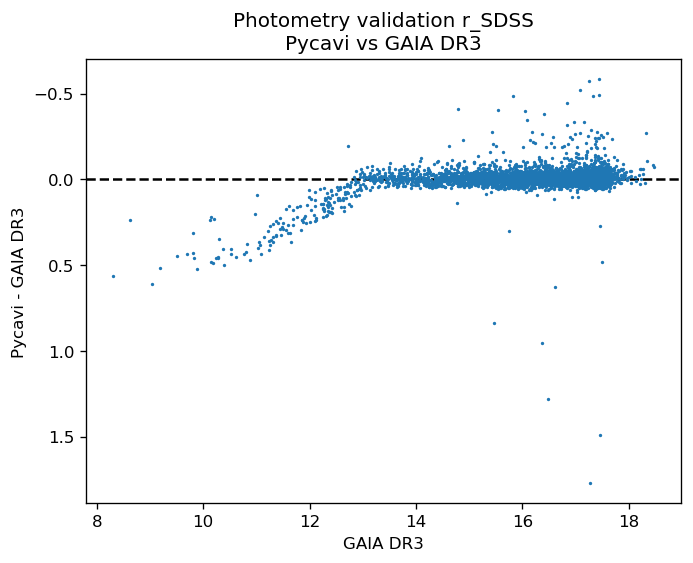

In [24]:
mag_r = mergedtable['MAG_PETRO_r_SDSS']
mag_r_gaia = mergedtable['r_sdss_mag_gaia']

fig, ax = plt.subplots(dpi=120)
ax.scatter(mag_r_gaia, mag_r - mag_r_gaia, s=1)
ax.axhline(0, ls='--', color='black', zorder=-1)
ax.invert_yaxis()
ax.set_xlabel('GAIA DR3')
ax.set_ylabel('Pycavi - GAIA DR3')
ax.set_title('Photometry validation r_SDSS\nPycavi vs GAIA DR3')
plt.show()

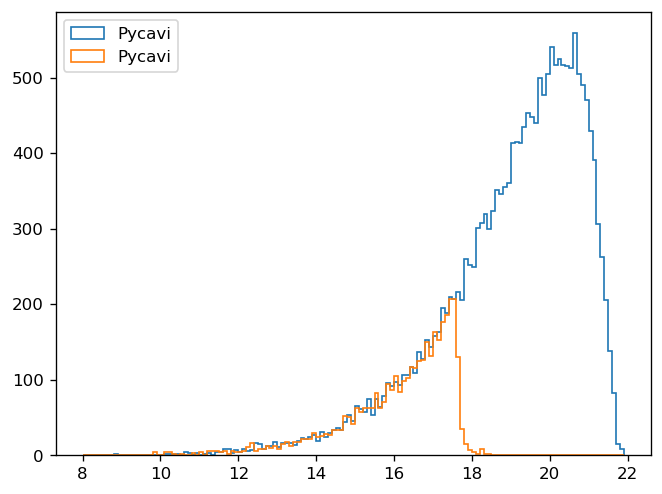

In [25]:
fig, ax = plt.subplots(dpi=120)
bins = np.arange(8, 22, 0.1)
ax.hist(mag_r, bins=bins, histtype='step', label='Pycavi')
ax.hist(mag_r_gaia, bins=bins, histtype='step', label='Pycavi')
ax.legend(loc='upper left')
plt.show()

### ellipticity

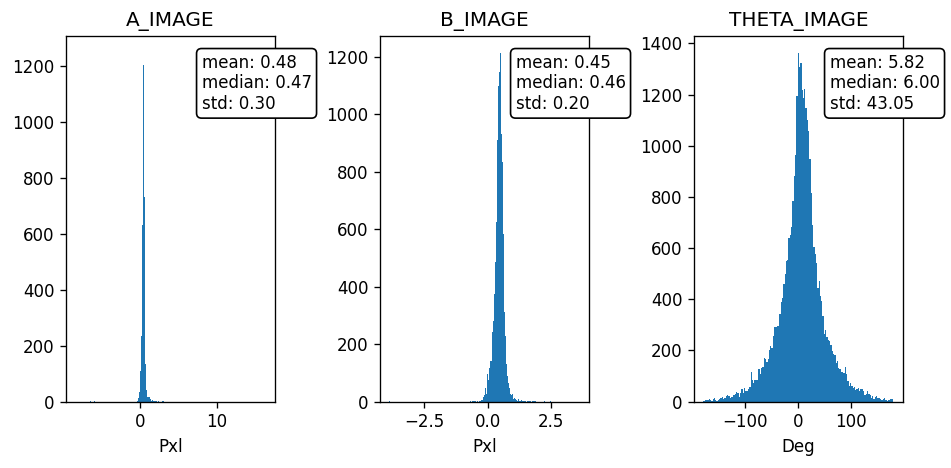

In [38]:
a_r = mergedtable['A_IMAGE_r_SDSS']
a_nb = mergedtable['A_IMAGE_NB_659']
b_r = mergedtable['B_IMAGE_r_SDSS']
b_nb = mergedtable['B_IMAGE_NB_659']
theta_r = mergedtable['THETA_IMAGE_r_SDSS']
theta_nb = mergedtable['THETA_IMAGE_NB_659']

median_dif_a = np.nanmedian(a_r-a_nb)
mean_dif_a = np.nanmean(a_r-a_nb)
std_dif_a = np.nanstd(a_r-a_nb)

median_dif_b = np.nanmedian(b_r-b_nb)
mean_dif_b = np.nanmean(b_r-b_nb)
std_dif_b = np.nanstd(b_r-b_nb)

median_dif_theta = np.nanmedian(theta_r-theta_nb)
mean_dif_theta = np.nanmean(theta_r-theta_nb)
std_dif_theta = np.nanstd(theta_r-theta_nb)

fig, ax = plt.subplots(ncols=3, figsize=(8,4), dpi=120)
ax[0].hist(a_r - a_nb, bins='fd')
ax[1].hist(b_r - b_nb, bins='fd')
ax[2].hist(theta_r - theta_nb, bins='fd')

ax[0].text(x=0.65, y=0.8, 
           s='mean: {:.2f}\nmedian: {:.2f}\nstd: {:.2f}'.format(mean_dif_a, median_dif_a, std_dif_a), 
           transform=ax[0].transAxes, bbox=dict(boxstyle='round', facecolor='white'))

ax[1].text(x=0.65, y=0.8, 
           s='mean: {:.2f}\nmedian: {:.2f}\nstd: {:.2f}'.format(mean_dif_b, median_dif_b, std_dif_b), 
           transform=ax[1].transAxes, bbox=dict(boxstyle='round', facecolor='white'))

ax[2].text(x=0.65, y=0.8, 
           s='mean: {:.2f}\nmedian: {:.2f}\nstd: {:.2f}'.format(mean_dif_theta, median_dif_theta, std_dif_theta), 
           transform=ax[2].transAxes, bbox=dict(boxstyle='round', facecolor='white'))

ax[0].set_title('A_IMAGE')
ax[1].set_title('B_IMAGE')
ax[2].set_title('THETA_IMAGE')

ax[0].set_xlabel('Pxl')
ax[1].set_xlabel('Pxl')
ax[2].set_xlabel('Deg')
plt.tight_layout()
plt.show()

### Clean and check of the merged catalogue

For the clean, remove all sources that are not detected in both catalogues.<br>
Pros: easier comparison with Gaia crossmatching.<br>
Cons: We lose some stars in the edge of the images.<br>

Combine the ra/dec, and reject sources with a difference larger than 1 arcsec from one another.<br>
Keep the rest of tags differentiated with the filter tag. One may be interested in study the differences between filters. <br>

In [48]:
basedir = '/home/lientur/Investigacion/OmegaCam/Work_dir/science/BD_Pav/Calibration_dir/'
cleantable = load_catalogue(basedir + 'BD_Pav_merged_catalogue.fits', extnumber=1)
print(cleantable.colnames)

['NUMBER_r_SDSS', 'EXT_NUMBER_r_SDSS', 'FLUX_ISO_r_SDSS', 'FLUXERR_ISO_r_SDSS', 'MAG_ISO_r_SDSS', 'MAGERR_ISO_r_SDSS', 'FLUX_AUTO_r_SDSS', 'FLUXERR_AUTO_r_SDSS', 'MAG_AUTO_r_SDSS', 'MAGERR_AUTO_r_SDSS', 'FLUX_PETRO_r_SDSS', 'FLUXERR_PETRO_r_SDSS', 'MAG_PETRO_r_SDSS', 'MAGERR_PETRO_r_SDSS', 'X_IMAGE_r_SDSS', 'Y_IMAGE_r_SDSS', 'A_IMAGE_r_SDSS', 'B_IMAGE_r_SDSS', 'THETA_IMAGE_r_SDSS', 'XWIN_IMAGE_r_SDSS', 'YWIN_IMAGE_r_SDSS', 'ERRX2WIN_IMAGE_r_SDSS', 'ERRY2WIN_IMAGE_r_SDSS', 'ERRXYWIN_IMAGE_r_SDSS', 'ERRX2WIN_WORLD_r_SDSS', 'ERRY2WIN_WORLD_r_SDSS', 'ERRXYWIN_WORLD_r_SDSS', 'ERRAWIN_IMAGE_r_SDSS', 'ERRBWIN_IMAGE_r_SDSS', 'ERRTHETAWIN_IMAGE_r_SDSS', 'FLAGS_r_SDSS', 'FLAGS_WEIGHT_r_SDSS', 'FLAGS_WIN_r_SDSS', 'FWHM_IMAGE_r_SDSS', 'ELONGATION_r_SDSS', 'ELLIPTICITY_r_SDSS', 'CLASS_STAR_r_SDSS', 'NUMBER_NB_659', 'EXT_NUMBER_NB_659', 'FLUX_ISO_NB_659', 'FLUXERR_ISO_NB_659', 'MAG_ISO_NB_659', 'MAGERR_ISO_NB_659', 'FLUX_AUTO_NB_659', 'FLUXERR_AUTO_NB_659', 'MAG_AUTO_NB_659', 'MAGERR_AUTO_NB_659', '

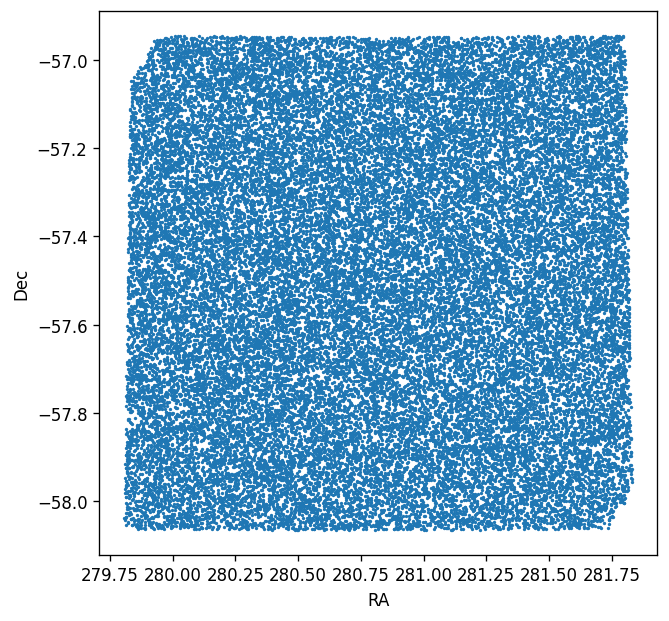

In [49]:
ra = cleantable['raj2000']
de = cleantable['dej2000']

fig, ax = plt.subplots(figsize=(6,6), dpi=120)
ax.scatter(ra, de, s=1)
ax.set_xlabel('RA')
ax.set_ylabel('Dec')
plt.show()

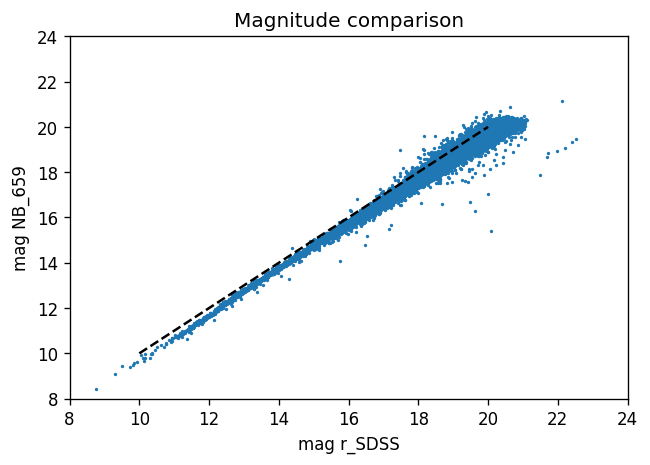

In [51]:
mag_r = cleantable['MAG_PETRO_r_SDSS']
mag_nb = cleantable['MAG_PETRO_NB_659']

fig, ax = plt.subplots(dpi=120)
ax.scatter(mag_r, mag_nb, s=1)
ax.plot([10,20],[10,20], ls='--', color='black')
ax.set_ylim(8,24)
ax.set_xlim(8,24)
ax.set_xlabel('mag r_SDSS')
ax.set_ylabel('mag NB_659')
ax.set_title('Magnitude comparison')
plt.show()

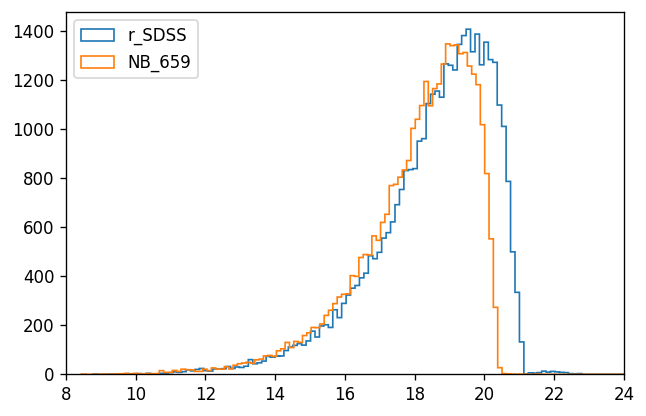

In [53]:
fig, ax = plt.subplots(dpi=120)

ax.hist(mag_r, bins='fd', label='r_SDSS', histtype='step')
ax.hist(mag_nb, bins='fd', label='NB_659', histtype='step')
ax.set_xlim(8,24)
ax.legend(loc='upper left')
plt.show()

### Combine the clean catalogue with Gaia

In [5]:
basedir = '/home/lientur/Investigacion/OmegaCam/Work_dir/science/BD_Pav/Calibration_dir/'
merged_clean_gaia = load_catalogue(basedir + 'BD_Pav_merged_catalogue.fits', extnumber=1)

### r_SDSS vs GAIA check

ZP:
PETRO: -0.01 mag
AUTO: -0.04 mag
ISO: -0.03 mag


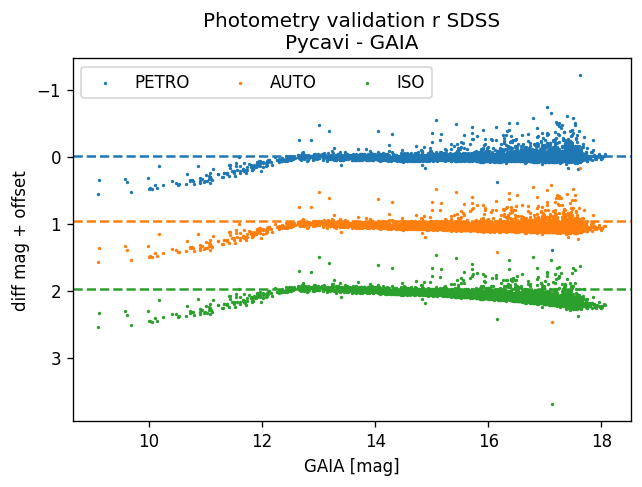

In [18]:
import matplotlib.pyplot as plt

def getzp(mag, mag_ref):
    sel = (mag_ref > 13) & (mag_ref < 16)
    return np.nanmedian(mag_ref[sel] - mag[sel])
    

mag_1_petro = merged_clean_gaia['MAG_PETRO_r_SDSS']
mag_1_auto = merged_clean_gaia['MAG_AUTO_r_SDSS']
mag_1_iso = merged_clean_gaia['MAG_ISO_r_SDSS']
mag_2 = merged_clean_gaia['r_SDSS_gaia']

zp_petro = getzp(mag_1_petro, mag_2)
zp_auto = getzp(mag_1_auto, mag_2)
zp_iso = getzp(mag_1_iso, mag_2)

print('ZP:')
print('PETRO: {:.2f} mag'.format(zp_petro))
print('AUTO: {:.2f} mag'.format(zp_auto))
print('ISO: {:.2f} mag'.format(zp_iso))

fig, ax = plt.subplots(dpi=120)
ax.scatter(mag_2, mag_1_petro-mag_2, s=1, label='PETRO')
ax.scatter(mag_2, 1+mag_1_auto-mag_2, s=1, label='AUTO')
ax.scatter(mag_2, 2+mag_1_iso-mag_2, s=1, label='ISO')
ax.axhline(zp_petro, ls='--', color='tab:blue')
ax.axhline(zp_auto+1, ls='--', color='tab:orange')
ax.axhline(zp_iso+2, ls='--', color='tab:green')
ax.invert_yaxis()

ax.legend(loc=0, ncols=3)
ax.set_xlabel('GAIA [mag]')
ax.set_ylabel('diff mag + offset')
ax.set_title('Photometry validation r SDSS\nPycavi - GAIA')

plt.savefig(basedir+'photometry_validation_GAIA.png', format='png', facecolor='white')
plt.show()

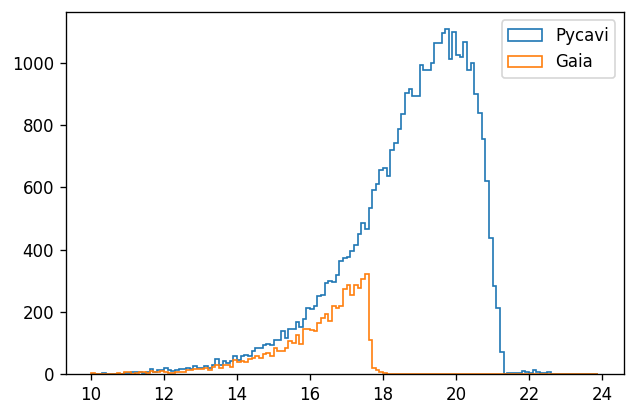

In [112]:
fig, ax = plt.subplots(dpi=120)
bins = np.arange(10, 24, 0.1)
ax.hist(mag_1_petro[mag_1_petro < 99], bins=bins, histtype='step', label='Pycavi')
ax.hist(mag_2, bins=bins, histtype='step', label='Gaia')
ax.legend(loc=0)
plt.show()

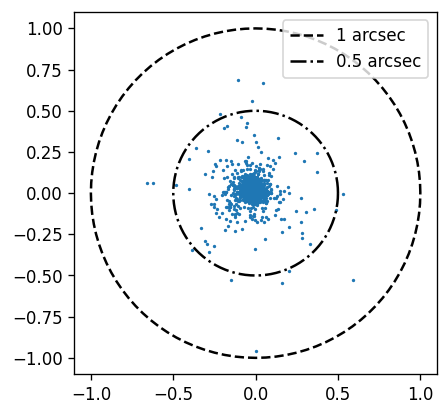

In [21]:
ra1 = merged_clean_gaia['raj2000']
ra2 = merged_clean_gaia['raj2000_gaia']
de1 = merged_clean_gaia['dej2000']
de2 = merged_clean_gaia['dej2000_gaia']

t = np.linspace(0, 2*np.pi, 101)
x = np.cos(t)
y = np.sin(t)

fig, ax = plt.subplots(dpi=120)
ax.scatter(3600*(ra1-ra2)*np.cos(np.nanmean(de1)), 3600*(de1-de2), s=1)
ax.plot(x, y, ls='--', color='black', label='1 arcsec')
ax.plot(0.5*x, 0.5*y, ls='-.', color='black', label='0.5 arcsec')
ax.set_aspect(1)
ax.legend(loc=0)

plt.show()

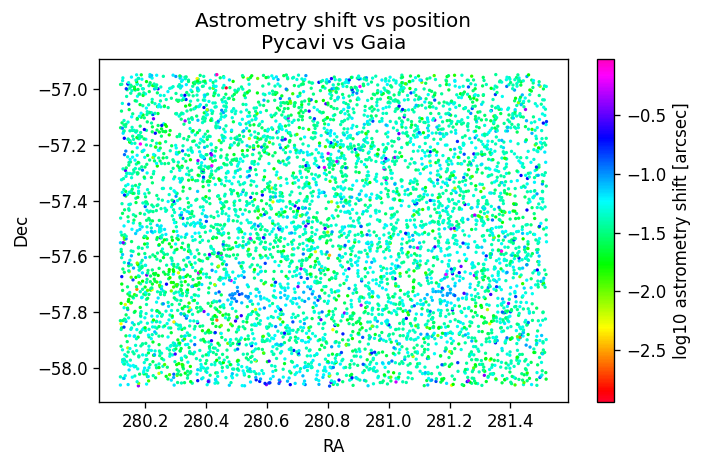

In [22]:
r = np.log10(3600*(((ra1-ra2)*np.cos(np.nanmean(de1)))**2 + (de1-de2)**2)**(1/2))

fig, ax = plt.subplots(dpi=120)
im = ax.scatter(ra1, de1, c=r, s=1, cmap='gist_rainbow')
fig.colorbar(im, ax=ax, label='log10 astrometry shift [arcsec]')
ax.set_title('Astrometry shift vs position\nPycavi vs Gaia')
ax.set_ylabel('Dec')
ax.set_xlabel('RA')
plt.tight_layout()
plt.savefig(basedir+'astrometry_validation_GAIA.png', format='png', facecolor='white')
plt.show()

### Validation against SkyMapper

In [11]:
target_name='/home/lientur/Investigacion/OmegaCam/Work_dir//science/BD_Pav/Calibration_dir/BD_Pav'

In [12]:
import urllib.request

sm_query_name = target_name+'_sm_query.csv'
py_merged_name = target_name + '_merged_catalogue.fits'

if not os.path.isfile(sm_query_name):
    
    headers_image = fits.getheader(images_to_check[i])
    sm_query = "http://skymapper.anu.edu.au/sm-cone/public/query?RA={}&DEC={}&SR={}&VERB=3&RESPONSEFORMAT=CSV".format(headers_image['RA'], headers_image['DEC'], 1.0)
    print(sm_query)

    with urllib.request.urlopen(sm_query) as f:
        charset = f.headers.get_content_charset()
        line_list = f.read().decode(charset).split('\r\n')

    # and here we write to file
    with open(sm_query_name, "w") as f:
        for aline in line_list:
            print(aline, file=f)
            
skymapper_table = pd.read_csv(sm_query_name)
skymapper_table = Table.from_pandas(skymapper_table)

for col in skymapper_table.colnames:
    skymapper_table.rename_column(col, col+'_sm')
    
py_merged_table = load_catalogue(py_merged_name, extnumber=1)

py_sm_matched_table = crossmatch_catalogues(py_merged_table, skymapper_table, 
                                            radec_tag_1=['raj2000', 'dej2000'], 
                                            radec_tag_2=['raj2000_sm', 'dej2000_sm'])

py_sm_matched_table.write(target_name+'_merged_catalogue_skymaper.fits', format='fits', overwrite=True)

In [93]:
print(skymapper_table.colnames)

['r_cntr_sm', 'object_id_sm', 'raj2000_sm', 'dej2000_sm', 'e_raj2000_sm', 'e_dej2000_sm', 'smss_j_sm', 'mean_epoch_sm', 'rms_epoch_sm', 'glon_sm', 'glat_sm', 'flags_sm', 'nimaflags_sm', 'ngood_sm', 'u_flags_sm', 'u_nimaflags_sm', 'u_ngood_sm', 'u_nclip_sm', 'v_flags_sm', 'v_nimaflags_sm', 'v_ngood_sm', 'v_nclip_sm', 'g_flags_sm', 'g_nimaflags_sm', 'g_ngood_sm', 'g_nclip_sm', 'r_flags_sm', 'r_nimaflags_sm', 'r_ngood_sm', 'r_nclip_sm', 'i_flags_sm', 'i_nimaflags_sm', 'i_ngood_sm', 'i_nclip_sm', 'z_flags_sm', 'z_nimaflags_sm', 'z_ngood_sm', 'z_nclip_sm', 'class_star_sm', 'chi2_psf_sm', 'flags_psf_sm', 'radius_petro_sm', 'mean_fwhm_sm', 'u_psf_sm', 'e_u_psf_sm', 'u_petro_sm', 'e_u_petro_sm', 'u_apc05_sm', 'e_u_apc05_sm', 'u_mmvar_sm', 'v_psf_sm', 'e_v_psf_sm', 'v_petro_sm', 'e_v_petro_sm', 'v_apc05_sm', 'e_v_apc05_sm', 'v_mmvar_sm', 'g_psf_sm', 'e_g_psf_sm', 'g_petro_sm', 'e_g_petro_sm', 'g_apc05_sm', 'e_g_apc05_sm', 'g_mmvar_sm', 'r_psf_sm', 'e_r_psf_sm', 'r_petro_sm', 'e_r_petro_sm', 'r_

In [95]:
print(py_sm_matched_table.colnames)

['r_cntr_sm', 'object_id_sm', 'raj2000_sm', 'dej2000_sm', 'e_raj2000_sm', 'e_dej2000_sm', 'smss_j_sm', 'mean_epoch_sm', 'rms_epoch_sm', 'glon_sm', 'glat_sm', 'flags_sm', 'nimaflags_sm', 'ngood_sm', 'u_flags_sm', 'u_nimaflags_sm', 'u_ngood_sm', 'u_nclip_sm', 'v_flags_sm', 'v_nimaflags_sm', 'v_ngood_sm', 'v_nclip_sm', 'g_flags_sm', 'g_nimaflags_sm', 'g_ngood_sm', 'g_nclip_sm', 'r_flags_sm', 'r_nimaflags_sm', 'r_ngood_sm', 'r_nclip_sm', 'i_flags_sm', 'i_nimaflags_sm', 'i_ngood_sm', 'i_nclip_sm', 'z_flags_sm', 'z_nimaflags_sm', 'z_ngood_sm', 'z_nclip_sm', 'class_star_sm', 'chi2_psf_sm', 'flags_psf_sm', 'radius_petro_sm', 'mean_fwhm_sm', 'u_psf_sm', 'e_u_psf_sm', 'u_petro_sm', 'e_u_petro_sm', 'u_apc05_sm', 'e_u_apc05_sm', 'u_mmvar_sm', 'v_psf_sm', 'e_v_psf_sm', 'v_petro_sm', 'e_v_petro_sm', 'v_apc05_sm', 'e_v_apc05_sm', 'v_mmvar_sm', 'g_psf_sm', 'e_g_psf_sm', 'g_petro_sm', 'e_g_petro_sm', 'g_apc05_sm', 'e_g_apc05_sm', 'g_mmvar_sm', 'r_psf_sm', 'e_r_psf_sm', 'r_petro_sm', 'e_r_petro_sm', 'r_

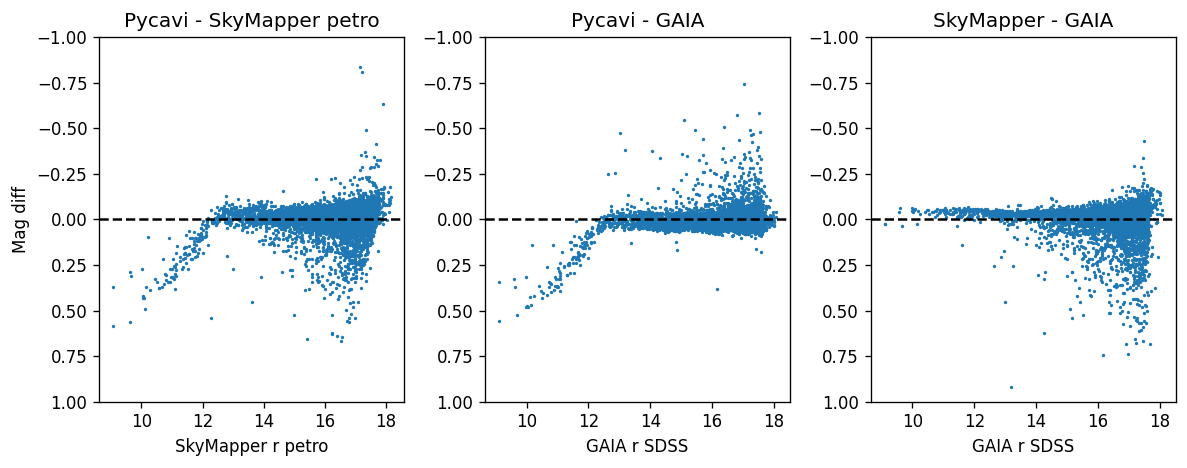

In [20]:
def getzp(mag, mag_ref):
    sel = (mag_ref > 13) & (mag_ref < 16)
    return np.nanmedian(mag_ref[sel] - mag[sel])

r_py_petro = py_sm_matched_table['MAG_PETRO_r_SDSS']
r_sm_petro = py_sm_matched_table['r_petro_sm']
r_gaia = py_sm_matched_table['r_SDSS_gaia']

sel = (r_py_petro < 25) & (r_sm_petro < 25) & (r_gaia < 25)

fig, ax = plt.subplots(ncols=3, figsize=(10,4), dpi=120)

ax[0].scatter(r_sm_petro[sel], r_py_petro[sel]-r_sm_petro[sel], s=1)
ax[0].set_xlabel('SkyMapper r petro')
ax[0].set_ylabel('Mag diff')
ax[0].set_title('Pycavi - SkyMapper petro')
ax[0].axhline(0.0, ls='--', color='black')
ax[0].set_ylim(-1,1)
ax[0].invert_yaxis()

ax[1].scatter(r_gaia[sel], r_py_petro[sel]-r_gaia[sel], s=1)
ax[1].set_xlabel('GAIA r SDSS')
ax[1].set_title('Pycavi - GAIA')
ax[1].axhline(0.0, ls='--', color='black')
ax[1].set_ylim(-1,1)
ax[1].invert_yaxis()

ax[2].scatter(r_gaia[sel], r_gaia[sel]-r_sm_petro[sel], s=1)
ax[2].set_xlabel('GAIA r SDSS')
ax[2].set_title('SkyMapper - GAIA')
ax[2].axhline(0.0, ls='--', color='black')
ax[2].set_ylim(-1,1)
ax[2].invert_yaxis()

plt.tight_layout()
plt.savefig(basedir+'photometry_validation_skymapper.png', format='png', facecolor='white')
plt.show()

## Comparison with VPHAS+

In [27]:
vphas_cat = load_catalogue('/home/lceledon/Investigacion/OmegaCam/Vphas_data/CN_Ori/ADP.2017-11-03T09:28:40.028.fits', extnumber=1)
for col in vphas_cat.colnames:
    vphas_cat.rename_column(col, col+'_vphas')

py_vphas_matched_table = crossmatch_catalogues(mergedtable, vphas_cat, 
                                               radec_tag_1=['raj2000', 'dej2000'], 
                                               radec_tag_2=['RA2000_vphas', 'DEC2000_vphas'])

In [39]:
py_vphas_matched_table = crossmatch_catalogues(vphas_cat, mergedtable,  
                                               radec_tag_1=['RA2000_vphas', 'DEC2000_vphas'], 
                                               radec_tag_2=['raj2000', 'dej2000'])

In [40]:
print(py_vphas_matched_table.colnames)

['IAUNAME_vphas', 'SOURCEID_vphas', 'RA2000_vphas', 'DEC2000_vphas', 'L_vphas', 'B_vphas', 'MERGEDCLASS_vphas', 'UMGPNT_vphas', 'UMGPNTERR_vphas', 'GMR2PNT_vphas', 'GMR2PNTERR_vphas', 'RMHAVPHASPNT_vphas', 'RMHAVPHASPNTERR_vphas', 'RMIPNT_vphas', 'RMIPNTERR_vphas', 'UMJD_vphas', 'UAPERMAG3_vphas', 'UAPERMAG3ERR_vphas', 'UAPERMAG4_vphas', 'UAPERMAG4ERR_vphas', 'UAPERMAG6_vphas', 'UAPERMAG6ERR_vphas', 'UGAUSIG_vphas', 'UELL_vphas', 'UPA_vphas', 'UERRBITS_vphas', 'UPPERRBITS_vphas', 'UAVERAGECONF_vphas', 'UCLASS_vphas', 'UXI_vphas', 'UETA_vphas', 'USEQNUM_vphas', 'GMJD_vphas', 'GAPERMAG3_vphas', 'GAPERMAG3ERR_vphas', 'GAPERMAG4_vphas', 'GAPERMAG4ERR_vphas', 'GAPERMAG6_vphas', 'GAPERMAG6ERR_vphas', 'GGAUSIG_vphas', 'GELL_vphas', 'GPA_vphas', 'GERRBITS_vphas', 'GPPERRBITS_vphas', 'GAVERAGECONF_vphas', 'GCLASS_vphas', 'GXI_vphas', 'GETA_vphas', 'GSEQNUM_vphas', 'R2MJD_vphas', 'R2APERMAG3_vphas', 'R2APERMAG3ERR_vphas', 'R2APERMAG4_vphas', 'R2APERMAG4ERR_vphas', 'R2APERMAG6_vphas', 'R2APERMAG6

/tmp/ipykernel_7156/1941220290.py:5: RuntimeWarning: Mean of empty slice
  mean_de = np.nanmean(de_py)


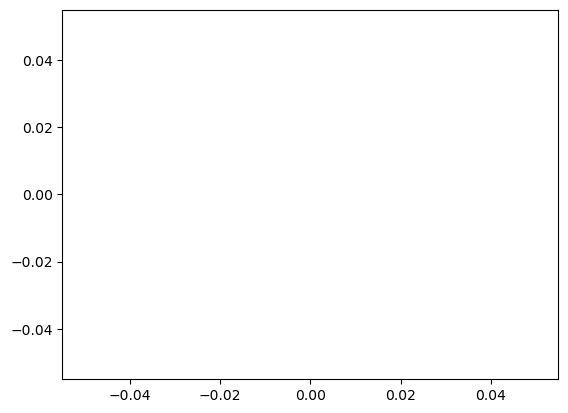

In [41]:
ra_py = py_vphas_matched_table['raj2000']
de_py = py_vphas_matched_table['dej2000']
ra_vphas = py_vphas_matched_table['RA2000_vphas']
de_vphas = py_vphas_matched_table['DEC2000_vphas']
mean_de = np.nanmean(de_py)

delta_ra = 3600*(ra_py - ra_vphas)
delta_de = 3600*np.cos(mean_de*np.pi/180)*(de_py - de_vphas)

fig, ax = plt.subplots()
ax.scatter(delta_ra, delta_de)
plt.show()

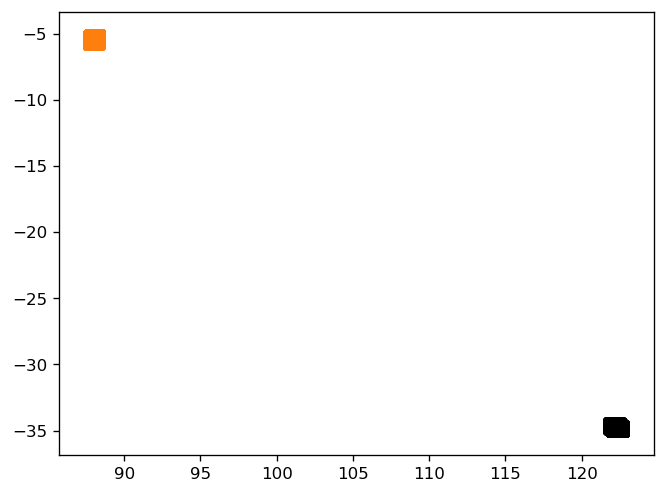

In [47]:
fig, ax = plt.subplots(dpi=120)

ax.scatter(ra_vphas, de_vphas, s=1, color='black', zorder=-1)
ax.scatter(ra_py, de_py, s=10, color='tab:orange')
plt.show()

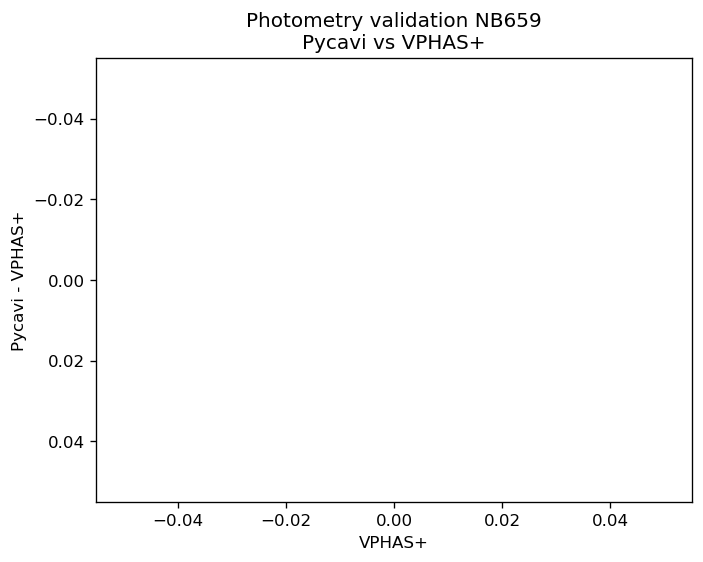

In [31]:
nb_py = py_vphas_matched_table['MAG_PETRO_NB_659']
nb_vphas = py_vphas_matched_table['HAVPHASAPERMAG4_vphas']

fig, ax = plt.subplots(dpi=120)
ax.scatter(nb_vphas, nb_py-nb_vphas, s=1)
ax.invert_yaxis()
ax.set_xlabel('VPHAS+')
ax.set_ylabel('Pycavi - VPHAS+')
ax.set_title('Photometry validation NB659\nPycavi vs VPHAS+')
plt.show()

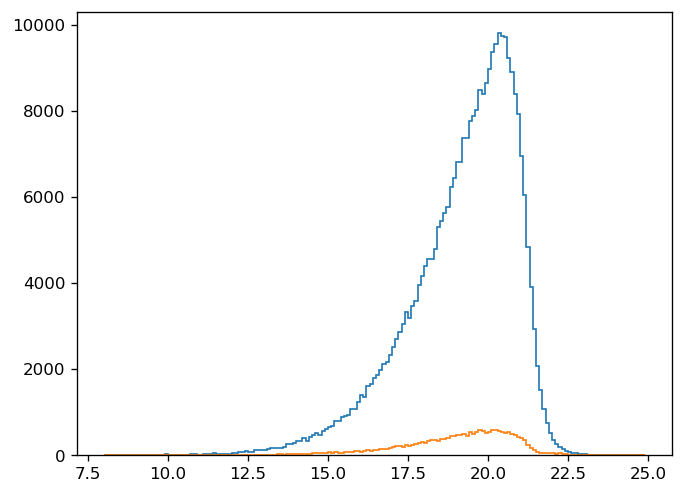

In [38]:
nb_py_0 = merged_table['MAG_PETRO_NB_659']

fig, ax = plt.subplots(dpi=120)

bins = np.arange(8, 25, 0.1)
ax.hist(nb_vphas, bins=bins, histtype='step')
ax.hist(nb_py_0, bins=bins, histtype='step')
plt.show()

In [11]:
df = pd.read_csv('/home/lceledon/Investigacion/OmegaCam/Work_dir/science/CP_Pup/Calibration_dir/gaia3_qry_CP_Pup_raw.csv')

print(df.columns)

Index(['SOURCE_ID', 'raj2000', 'raj2000_error', 'dej2000', 'dej2000_error',
       'parallax', 'parallax_error', 'pmra', 'pmra_error', 'pmdec',
       'pmdec_error', 'radial_velocity', 'radial_velocity_error', 'g_mag',
       'g_mag_error', 'bp_mag', 'bp_mag_error', 'rp_mag', 'rp_mag_error',
       'u_psf', 'e_u_psf', 'g_psf', 'e_g_psf', 'r_psf', 'e_r_psf', 'i_psf',
       'e_i_psf', 'z_psf', 'e_z_psf', 'u_SDSS', 'g_SDSS', 'r_SDSS', 'i_SDSS',
       'z_SDSS', 'class_star'],
      dtype='object')
